# 07 video preparation

This notebook turns the raw clips into one H.264 stream per episode and camera.

## 1. Setup

Load the config and the earlier reports, and check ffmpeg and the disk space.

In [1]:
import json, re, hashlib, shutil, subprocess, sys, time, zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import av
import cv2
from tqdm import tqdm

# top flags
FORCE = True  # on for this run
PRESET = "veryfast"
ROTATE_HEAD_180 = True
CRF_CANDIDATES = [24, 26, 28, 30, 32]
TARGET_SSIM = 0.98
BITRATE_CAP_MBPS = 8.0
MAKE_MP4_COPY = False

# fixed facts about the capture
FPS = 30
CLIP_FRAMES = 5400
WIDTH, HEIGHT = 1920, 1080
DEVICES = ["head", "left", "right"]
CAM = {"head": "cam_high", "left": "cam_left_wrist", "right": "cam_right_wrist"}
CAM_NAMES = [CAM[d] for d in DEVICES]
ALIAS = {"head": "head", "left": "left", "right": "right",
         "cam_high": "head", "cam_left_wrist": "left", "cam_right_wrist": "right"}

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

PROJECT_ROOT = Path.cwd().parent
cfg_path = PROJECT_ROOT / "configs" / "config.yaml"
if not cfg_path.exists():
    raise SystemExit(f"configs\\config.yaml not found in {PROJECT_ROOT}. run this notebook from the notebooks folder.")
cfg = yaml.safe_load(cfg_path.read_text(encoding="utf-8")) or {}

RAW = PROJECT_ROOT / "raw"
REPORTS = PROJECT_ROOT / "reports"
EPISODES = PROJECT_ROOT / "episodes"
WORK = PROJECT_ROOT / "work" / "07"
WORK.mkdir(parents=True, exist_ok=True)
RUN_UTC = datetime.now(timezone.utc).isoformat(timespec="seconds")

# tool versions
def tool_version(name):
    try:
        r = subprocess.run([name, "-version"], capture_output=True, text=True)
    except FileNotFoundError:
        raise SystemExit(f"{name} not found on PATH")
    return r.stdout.splitlines()[0] if r.stdout else ""

FFMPEG_VERSION = tool_version("ffmpeg")
FFPROBE_VERSION = tool_version("ffprobe")
print(FFMPEG_VERSION)
print(FFPROBE_VERSION)
encoders = subprocess.run(["ffmpeg", "-hide_banner", "-encoders"], capture_output=True, text=True).stdout
filters = subprocess.run(["ffmpeg", "-hide_banner", "-filters"], capture_output=True, text=True).stdout
print("libx264 encoder:", "libx264" in encoders, "| libvmaf filter:", "libvmaf" in filters)
if "libx264" not in encoders:
    raise SystemExit("this ffmpeg has no libx264")

# disk space
free_gb = shutil.disk_usage(PROJECT_ROOT).free / 1e9
print(f"free disk: {free_gb:.1f} GB")
if free_gb < 20:
    raise SystemExit("less than 20 GB free, stopping")

# earlier reports
eps = pd.read_csv(REPORTS / "05_episodes.csv")
summary06 = json.loads((REPORTS / "06_summary.json").read_text(encoding="utf-8"))
EP_IDS = [str(x) for x in summary06["episode_ids"]]
if len(EP_IDS) != len(eps):
    raise SystemExit(f"06_summary has {len(EP_IDS)} episode ids but 05_episodes.csv has {len(eps)} rows")
clock = pd.read_csv(REPORTS / "04_chunk_clock_fit.csv")
manifest_raw = pd.read_csv(REPORTS / "raw_manifest.csv")

counts = pd.DataFrame({"episode_id": EP_IDS})
for d in DEVICES:
    counts[d] = (eps[f"{d}_n_stop_excl"] - eps[f"{d}_n_start"]).to_numpy()
print(len(EP_IDS), "episodes, frames per device:")
show_counts = counts.to_string(index=False)
print(show_counts)

# keys of the first npz from notebook 06
try:
    z = np.load(EPISODES / EP_IDS[0] / "frames_head.npz", allow_pickle=False)
    print("keys of first npz:", list(z.files))
    z.close()
except Exception as e:
    print("could not open the first npz:", e)

ffmpeg version 9.0.2-full_build-www.gyan.dev Copyright (c) 2000-2026 the FFmpeg developers
ffprobe version 9.0.2-full_build-www.gyan.dev Copyright (c) 2007-2026 the FFmpeg developers
libx264 encoder: True | libvmaf filter: True
free disk: 67.3 GB
4 episodes, frames per device:
                    episode_id  head  left  right
vendorX_2026-10-11_op01_000001 21240 21239  21239
vendorX_2026-10-11_op01_000002  9390  9390   9390
vendorX_2026-10-11_op01_000003 10410 10410  10409
vendorX_2026-10-11_op01_000004 18000 17999  17999
keys of first npz: ['ts_session_us', 'flags', 'source_clip', 'local_i', 'global_n', 'acc', 'gyro', 'source_clips']


## Helper functions

Small functions that the later steps use.

In [2]:
def fail(step, e):
    print(f"problem in {step}: {type(e).__name__}: {e}")


def run(cmd):
    return subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace")


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 22), b""):
            h.update(block)
    return h.hexdigest()


def show(df, n=50):
    print(df.head(n).to_string(index=False))
    if len(df) > n:
        print(f"... {len(df) - n} more rows not shown")


def luma(frame):
    # grey plane of a decoded frame, padding cut off
    p = frame.planes[0]
    a = np.frombuffer(p, dtype=np.uint8)[: p.line_size * frame.height]
    return a.reshape(frame.height, p.line_size)[:, : frame.width]


# timestamp count in the npz files of notebook 06
TS_NAMES = ["t_s", "ts", "timestamps", "timestamp", "t", "time_s", "time", "pts_s", "pts"]

def ts_len(path):
    z = np.load(path, allow_pickle=False)
    try:
        keys = list(z.files)
        key = next((k for k in TS_NAMES if k in keys), None)
        if key is None:
            key = next((k for k in keys if "time" in k.lower() or "stamp" in k.lower()), None)
        if key is None:
            key = next((k for k in keys if z[k].ndim == 1), None)
        return key, (int(z[key].shape[0]) if key else None)
    finally:
        z.close()


# source clips from the manifests
clock["dev"] = clock["device"].map(lambda s: ALIAS.get(str(s).strip().lower(), str(s)))
vid = manifest_raw[manifest_raw["kind"] == "video"].copy()
if "dup_suffix" in vid.columns:
    vid = vid[vid["dup_suffix"].isna() | (vid["dup_suffix"].astype(str).str.strip() == "")]
vid["rel_norm"] = vid["rel_path"].astype(str).str.replace("\\", "/", regex=False)
vid["dev"] = vid["device"].map(lambda s: ALIAS.get(str(s).strip().lower(), str(s)))

_clip_cache = {}

def clip_info(dev, rank):
    key = (dev, int(rank))
    if key in _clip_cache:
        return _clip_cache[key]
    m = clock[(clock["dev"] == dev) & (clock["rank"] == int(rank))]
    if m.empty:
        raise KeyError(f"no clip for {dev} rank {rank} in the clock fit")
    base = str(m.iloc[0]["base"])
    if base.lower().endswith(".mp4"):
        base = base[:-4]
    cand = vid[vid["rel_norm"].str.endswith(base + ".mp4")]
    if (cand["dev"] == dev).any():
        cand = cand[cand["dev"] == dev]
    if cand.empty:
        raise KeyError(f"{base} is not in the raw manifest")
    row = cand.loc[cand["rel_norm"].str.len().idxmin()]
    path = RAW / Path(row["rel_norm"])
    if not path.exists():
        raise FileNotFoundError(str(path))
    info = {"base": base, "path": path, "rel_path": row["rel_norm"], "sha256": str(row["sha256"])}
    _clip_cache[key] = info
    return info


def source_info(dev, n0, nframes):
    # clips that hold global frames n0 .. n0 + nframes - 1
    r0 = n0 // CLIP_FRAMES + 1
    r1 = (n0 + nframes - 1) // CLIP_FRAMES + 1
    infos = [clip_info(dev, r) for r in range(r0, r1 + 1)]
    return r0, r1, n0 % CLIP_FRAMES, infos


def write_concat(infos, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    lines = []
    for i in infos:
        p = i["path"] if isinstance(i, dict) else i
        s = Path(p).resolve().as_posix().replace("'", "'\\''")
        lines.append(f"file '{s}'")
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return path


def vf_chain(dev, start, n):
    f = [f"trim=start_frame={start}:end_frame={start + n}", "setpts=N/(30*TB)"]
    if dev == "head" and ROTATE_HEAD_180:
        f += ["hflip", "vflip"]
    f += ["scale=in_range=pc:out_range=tv:out_color_matrix=bt709", "format=yuv420p"]
    return ",".join(f)


COLOUR_ARGS = ["-color_range", "tv", "-colorspace", "bt709", "-color_primaries", "bt709", "-color_trc", "bt709"]

def x264_args(crf):
    return (["-c:v", "libx264", "-preset", PRESET, "-crf", str(crf), "-profile:v", "high", "-level", "4.1",
             "-pix_fmt", "yuv420p", "-g", "30", "-keyint_min", "30", "-sc_threshold", "0", "-bf", "0",
             "-an"] + COLOUR_ARGS + ["-x264-params", "repeat-headers=1:aud=1"])

LOSSLESS_ARGS = (["-c:v", "libx264", "-qp", "0", "-preset", "veryfast", "-pix_fmt", "yuv420p", "-an"]
                 + COLOUR_ARGS)


def build_cmd(list_path, vf, args, out, nframes, fmt=None):
    cmd = ["ffmpeg", "-hide_banner", "-loglevel", "error", "-y",
           "-f", "concat", "-safe", "0", "-i", str(list_path),
           "-vf", vf, "-fps_mode", "passthrough", "-frames:v", str(nframes)] + args
    if fmt:
        cmd += ["-f", fmt]
    cmd.append(str(out))
    return cmd

## 2. Encode plan

Work out which source clips and frames go into each output stream.

In [3]:
plan = pd.DataFrame()
try:
    plan_rows = []
    for ei, eid in enumerate(EP_IDS):
        row = eps.iloc[ei]
        for dev in DEVICES:
            n0 = int(row[f"{dev}_n_start"])
            n1 = int(row[f"{dev}_n_stop_excl"])
            nf = n1 - n0
            rec = {"episode_id": eid, "camera": CAM[dev], "device": dev,
                   "n_start": n0, "n_stop_excl": n1, "frames": nf,
                   "first_clip": "", "last_clip": "", "start_frame": n0 % CLIP_FRAMES,
                   "source_files": [], "out_path": str(EPISODES / eid / "video" / f"{CAM[dev]}.h264"),
                   "ok": False}
            try:
                r0, r1, sf, infos = source_info(dev, n0, nf)
                rec.update(first_clip=infos[0]["base"], last_clip=infos[-1]["base"], start_frame=sf,
                           source_files=[str(i["path"]) for i in infos], ok=nf > 0)
            except Exception as e:
                fail(f"plan {eid} {dev}", e)
            plan_rows.append(rec)
    plan = pd.DataFrame(plan_rows)
    to_save = plan.copy()
    to_save["source_files"] = to_save["source_files"].map(lambda l: ";".join(l))
    to_save.to_csv(REPORTS / "07_encode_plan.csv", index=False)
    view = plan[["episode_id", "camera", "n_start", "n_stop_excl", "frames", "first_clip", "last_clip", "start_frame"]].copy()
    view["n_src"] = plan["source_files"].map(len)
    show(view)
except Exception as e:
    fail("encode plan", e)

                    episode_id          camera  n_start  n_stop_excl  frames    first_clip     last_clip  start_frame  n_src
vendorX_2026-10-11_op01_000001        cam_high     8159        29399   21240 a45140-H-0037 a45140-H-0041         2759      5
vendorX_2026-10-11_op01_000001  cam_left_wrist     8161        29400   21239 a60617-H-0021 a60617-H-0025         2761      5
vendorX_2026-10-11_op01_000001 cam_right_wrist     8161        29400   21239 a59879-H-0027 a59879-H-0031         2761      5
vendorX_2026-10-11_op01_000002        cam_high    30959        40349    9390 a45140-H-0041 a45140-H-0043         3959      3
vendorX_2026-10-11_op01_000002  cam_left_wrist    30960        40350    9390 a60617-H-0025 a60617-H-0027         3960      3
vendorX_2026-10-11_op01_000002 cam_right_wrist    30960        40350    9390 a59879-H-0031 a59879-H-0033         3960      3
vendorX_2026-10-11_op01_000003        cam_high    42149        52559   10410 a45140-H-0043 a45140-H-0045         4349      3


## 3. CRF test

Encode a 30 second excerpt of every camera at each CRF and compare it with a lossless copy.

In [4]:
test_csv = REPORTS / "07_encode_test.csv"
test_dir = WORK / "crf_test"
EXCERPT = 900
CRF = None
test_df = None


def measure(enc, ref):
    # mean ssim and psnr of enc against the lossless ref
    # both raw h264, same frame-index clock so frames pair one to one
    cmd = ["ffmpeg", "-hide_banner", "-nostats",
           "-framerate", str(FPS), "-f", "h264", "-i", str(enc),
           "-framerate", str(FPS), "-f", "h264", "-i", str(ref),
           "-lavfi", "[0:v]setpts=N/(30*TB)[a];[1:v]setpts=N/(30*TB)[b];[a]split[a1][a2];[b]split[b1][b2];[a1][b1]ssim[o1];[a2][b2]psnr[o2]",
           "-map", "[o1]", "-f", "null", "-", "-map", "[o2]", "-f", "null", "-"]
    err = run(cmd).stderr
    s = re.search(r"SSIM .*?All:([0-9.]+)", err)
    p = re.search(r"PSNR .*?average:([0-9.]+|inf)", err)
    return (float(s.group(1)) if s else np.nan), (float(p.group(1)) if p else np.nan)


try:
    if test_csv.exists() and not FORCE:
        test_df = pd.read_csv(test_csv)
        print("using existing", test_csv.name)
    else:
        rows = []
        test_dir.mkdir(parents=True, exist_ok=True)
        ep1 = plan[(plan["episode_id"] == EP_IDS[0]) & plan["ok"]]
        for _, p in ep1.iterrows():
            cam, dev = p["camera"], p["device"]
            nf = min(EXCERPT, int(p["frames"]))
            n0 = int(p["n_start"]) + (int(p["frames"]) - nf) // 2
            r0, r1, sf, infos = source_info(dev, n0, nf)
            lst = write_concat(infos, test_dir / f"{cam}_list.txt")
            vf = vf_chain(dev, sf, nf)
            ref = test_dir / f"{cam}_ref.h264"
            r = run(build_cmd(lst, vf, LOSSLESS_ARGS, ref, nf, fmt="h264"))
            if r.returncode != 0 or not ref.exists():
                print(f"problem: lossless reference failed for {cam}")
                print(r.stderr[-400:])
                continue
            for crf in tqdm(CRF_CANDIDATES, desc=cam, leave=False):
                enc = test_dir / f"{cam}_crf{crf}.h264"
                r = run(build_cmd(lst, vf, x264_args(crf), enc, nf, fmt="h264"))
                if r.returncode != 0 or not enc.exists():
                    print(f"problem: test encode failed for {cam} crf {crf}")
                    print(r.stderr[-400:])
                    continue
                ssim, psnr = measure(enc, ref)
                nbytes = enc.stat().st_size
                rows.append({"camera": cam, "device": dev, "crf": crf, "frames": nf, "bytes": nbytes,
                             "mbps": round(nbytes * 8 / (nf / FPS) / 1e6, 3),
                             "ssim": round(ssim, 5), "psnr": round(psnr, 2)})
            ref.unlink(missing_ok=True)
        test_df = pd.DataFrame(rows)
        test_df.to_csv(test_csv, index=False)
        shutil.rmtree(test_dir, ignore_errors=True)
    show(test_df)
    # psnr of a good encode is far above 38 db, so a low value means the frames are not paired
    best_psnr = test_df["psnr"].max() if len(test_df) else np.nan
    if not best_psnr >= 38:
        print(f"highest psnr in the table is {best_psnr} dB, below 38 dB.")
        print("the measurement is probably misaligned (or the test failed), stopping before the long encode.")
        raise SystemExit("crf test psnr too low")
except Exception as e:
    fail("crf test", e)

         camera device  crf  frames    bytes   mbps    ssim  psnr
       cam_high   head   24     900 43684617 11.649 0.98035 37.00
       cam_high   head   26     900 34069405  9.085 0.97563 35.47
       cam_high   head   28     900 26015298  6.937 0.96958 33.95
       cam_high   head   30     900 19406088  5.175 0.96196 32.43
       cam_high   head   32     900 14023789  3.740 0.95223 30.89
 cam_left_wrist   left   24     900 24090018  6.424 0.98501 42.47
 cam_left_wrist   left   26     900 18920421  5.045 0.98215 41.17
 cam_left_wrist   left   28     900 14728401  3.928 0.97862 39.85
 cam_left_wrist   left   30     900 11387179  3.037 0.97425 38.51
 cam_left_wrist   left   32     900  8750395  2.333 0.96879 37.18
cam_right_wrist  right   24     900 13525995  3.607 0.98818 46.31
cam_right_wrist  right   26     900 10075029  2.687 0.98664 45.20
cam_right_wrist  right   28     900  7481088  1.995 0.98485 44.01
cam_right_wrist  right   30     900  5649749  1.507 0.98283 42.75
cam_right_

In [5]:
# pick the crf
try:
    choice = {}
    for cam in CAM_NAMES:
        t = test_df[test_df["camera"] == cam]
        if t.empty:
            print(f"no test rows for {cam}")
            continue
        both = t[(t["ssim"] >= TARGET_SSIM) & (t["mbps"] <= BITRATE_CAP_MBPS)]
        if len(both):
            c = int(both["crf"].max())
            why = "highest crf with ssim and bitrate both ok"
        else:
            q = t[t["ssim"] >= TARGET_SSIM]
            if len(q):
                c = int(q.sort_values("mbps").iloc[0]["crf"])
                why = "FLAG no crf met both, lowest bitrate that reaches the ssim target"
            else:
                c = int(t.sort_values("ssim").iloc[-1]["crf"])
                why = "FLAG ssim target not reached, best ssim taken"
        choice[cam] = (c, why)
        print(f"{cam}: crf {c} ({why})")
    if choice:
        CRF = min(v[0] for v in choice.values())
        setters = [cam for cam, v in choice.items() if v[0] == CRF]
        print(f"one crf for all cameras: {CRF} (lowest of the three, set by {', '.join(setters)})")
        for cam in CAM_NAMES:
            r = test_df[(test_df["camera"] == cam) & (test_df["crf"] == CRF)]
            if r.empty:
                continue
            r = r.iloc[0]
            note = []
            if r["mbps"] > BITRATE_CAP_MBPS:
                note.append("above the bitrate cap")
            if r["ssim"] < TARGET_SSIM:
                note.append("below the ssim target")
            print(f"  {cam} at crf {CRF}: {r['mbps']} Mbps, ssim {r['ssim']}" + (" -> " + ", ".join(note) if note else ""))
    else:
        print("no crf choice could be made")
except Exception as e:
    fail("crf choice", e)

cam_high: crf 24 (FLAG no crf met both, lowest bitrate that reaches the ssim target)
cam_left_wrist: crf 26 (highest crf with ssim and bitrate both ok)
cam_right_wrist: crf 32 (highest crf with ssim and bitrate both ok)
one crf for all cameras: 24 (lowest of the three, set by cam_high)
  cam_high at crf 24: 11.649 Mbps, ssim 0.98035 -> above the bitrate cap
  cam_left_wrist at crf 24: 6.424 Mbps, ssim 0.98501
  cam_right_wrist at crf 24: 3.607 Mbps, ssim 0.98818


## 4. Final encode

Encode the 12 streams, one ffmpeg call per episode and camera.

In [6]:
enc_log = []
try:
    if CRF is None:
        CRF = min(CRF_CANDIDATES)
        print("no crf choice available, using", CRF)
    old_manifest = REPORTS / "07_video_manifest.csv"
    done = set()
    if old_manifest.exists() and not FORCE:
        om = pd.read_csv(old_manifest)
        done = set(om.loc[om["sha256"].notna(), "file"].astype(str))
    cmd_lines = []

    def hms(s):
        s = int(round(s))
        return f"{s // 3600}:{s % 3600 // 60:02d}:{s % 60:02d}"

    def will_skip(p):
        o = Path(p["out_path"])
        return o.exists() and str(o.relative_to(PROJECT_ROOT)) in done and not FORCE

    n_jobs = int(sum(1 for _, p in plan.iterrows() if p["ok"] and not will_skip(p)))
    frames_left = int(sum(int(p["frames"]) for _, p in plan.iterrows() if p["ok"] and not will_skip(p)))
    frames_done, time_done, n_done = 0, 0.0, 0
    t_start = time.time()
    for j, (_, p) in enumerate(tqdm(list(plan.iterrows()), desc="encode")):
        eid, cam = p["episode_id"], p["camera"]
        try:
            if not p["ok"]:
                tqdm.write(f"skip {eid} {cam}: plan row not usable")
                continue
            out = Path(p["out_path"])
            rel = str(out.relative_to(PROJECT_ROOT))
            out.parent.mkdir(parents=True, exist_ok=True)
            nf = int(p["frames"])
            lst = write_concat(p["source_files"], WORK / "lists" / f"{eid}_{cam}.txt")
            cmd = build_cmd(lst, vf_chain(p["device"], int(p["start_frame"]), nf), x264_args(CRF), out, nf, fmt="h264")
            line = subprocess.list2cmdline(cmd)
            cmd_lines.append(f"# {eid} {cam}\n{line}\n")
            if j == 0:
                tqdm.write("first command:\n" + line)
            if out.exists() and rel in done and not FORCE:
                tqdm.write(f"{eid} {cam}: already done, skipped")
                enc_log.append({"episode_id": eid, "camera": cam, "status": "skipped", "fps": None})
            else:
                t0 = time.time()
                r = run(cmd)
                dt = time.time() - t0
                if r.returncode != 0 or not out.exists() or out.stat().st_size == 0:
                    tqdm.write(f"problem: encode failed for {eid} {cam}")
                    tqdm.write(r.stderr[-500:])
                    out.unlink(missing_ok=True)
                    enc_log.append({"episode_id": eid, "camera": cam, "status": "failed", "fps": None})
                    frames_left -= nf
                    n_done += 1
                    continue
                frames_done += nf
                time_done += dt
                frames_left -= nf
                n_done += 1
                eta = frames_left / (frames_done / time_done)
                tqdm.write(f"{eid} {cam}: {nf} frames in {hms(dt)}, {nf / dt:.1f} fps | "
                           f"job {n_done} of {n_jobs}, elapsed {hms(time.time() - t_start)}, about {hms(eta)} left")
                enc_log.append({"episode_id": eid, "camera": cam, "status": "done", "fps": round(nf / dt, 1)})
            if MAKE_MP4_COPY and out.exists():
                mp4 = out.with_suffix(".mp4")
                if FORCE or not mp4.exists():
                    r = run(["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-framerate", str(FPS),
                             "-i", str(out), "-c", "copy", str(mp4)])
                    if r.returncode != 0:
                        tqdm.write(f"problem: mp4 copy failed for {eid} {cam}: {r.stderr[-200:]}")
        except Exception as e:
            fail(f"encode {eid} {cam}", e)
    (REPORTS / "07_commands.txt").write_text("\n".join(cmd_lines), encoding="utf-8")
    print("commands saved to reports\\07_commands.txt")
except Exception as e:
    fail("final encode", e)

encode:   0%|          | 0/12 [00:00<?, ?it/s]

first command:
ffmpeg -hide_banner -loglevel error -y -f concat -safe 0 -i "c:\workstation\3RD YEAR\ego_pipeline\work\07\lists\vendorX_2026-10-11_op01_000001_cam_high.txt" -vf trim=start_frame=2759:end_frame=23999,setpts=N/(30*TB),hflip,vflip,scale=in_range=pc:out_range=tv:out_color_matrix=bt709,format=yuv420p -fps_mode passthrough -frames:v 21240 -c:v libx264 -preset veryfast -crf 24 -profile:v high -level 4.1 -pix_fmt yuv420p -g 30 -keyint_min 30 -sc_threshold 0 -bf 0 -an -color_range tv -colorspace bt709 -color_primaries bt709 -color_trc bt709 -x264-params repeat-headers=1:aud=1 -f h264 "c:\workstation\3RD YEAR\ego_pipeline\episodes\vendorX_2026-10-11_op01_000001\video\cam_high.h264"


encode:   8%|▊         | 1/12 [05:08<56:31, 308.31s/it]

vendorX_2026-10-11_op01_000001 cam_high: 21240 frames in 0:05:08, 68.9 fps | job 1 of 12, elapsed 0:05:08, about 0:37:42 left


encode:  17%|█▋        | 2/12 [10:32<52:59, 317.94s/it]

...

vendorX_2026-10-11_op01_000004 cam_high: 18000 frames in 0:04:05, 73.5 fps | job 10 of 12, elapsed 0:32:29, about 0:08:17 left


encode:  92%|█████████▏| 11/12 [35:13<02:46, 166.91s/it]

vendorX_2026-10-11_op01_000004 cam_left_wrist: 17999 frames in 0:02:45, 109.3 fps | job 11 of 12, elapsed 0:35:13, about 0:03:59 left


encode: 100%|██████████| 12/12 [38:32<00:00, 192.74s/it]

vendorX_2026-10-11_op01_000004 cam_right_wrist: 17999 frames in 0:03:20, 90.1 fps | job 12 of 12, elapsed 0:38:33, about 0:00:00 left
commands saved to reports\07_commands.txt


## 5. Access units

Split every stream into access units using the start codes and the access unit delimiters.

In [7]:
def parse_au(path):
    data = path.read_bytes()
    starts, types = [], []
    pos = data.find(b"\x00\x00\x01")
    while pos != -1:
        if pos + 3 >= len(data):
            break
        starts.append(pos - 1 if pos > 0 and data[pos - 1] == 0 else pos)
        types.append(data[pos + 3] & 31)
        pos = data.find(b"\x00\x00\x01", pos + 3)
    starts = np.array(starts, dtype=np.int64)
    types = np.array(types, dtype=np.int64)
    is_aud = types == 9
    n_au = int(is_aud.sum())
    au_id = np.cumsum(is_aud) - 1
    keep = au_id >= 0

    def per_au(mask):
        return np.bincount(au_id[keep & mask], minlength=n_au)

    offsets = starts[is_aud]
    sizes = np.diff(np.append(offsets, len(data)))
    return {"offsets": offsets, "sizes": sizes,
            "is_key": per_au(types == 5) > 0,
            "n_sps": per_au(types == 7), "n_pps": per_au(types == 8),
            "n_vcl": per_au((types == 1) | (types == 5)),
            "frame_index": np.arange(n_au),
            "first_is_aud": np.array(bool(len(types) and types[0] == 9))}


AU = {}
au_rows = []
for _, p in plan.iterrows():
    eid, cam = p["episode_id"], p["camera"]
    try:
        out = Path(p["out_path"])
        if not out.exists():
            print(f"missing stream for {eid} {cam}")
            continue
        au_path = out.with_name(out.stem + "_au.npz")
        if au_path.exists() and not FORCE:
            z = np.load(au_path)
            d = {k: z[k] for k in z.files}
            z.close()
        else:
            d = parse_au(out)
            np.savez(au_path, **d)
        AU[(eid, cam)] = d
        au_rows.append({"episode_id": eid, "camera": cam, "units": len(d["offsets"]),
                        "keyframes": int(d["is_key"].sum()), "sps": int(d["n_sps"].sum()),
                        "pps": int(d["n_pps"].sum()), "empty_units": int((d["n_vcl"] == 0).sum() + (d["sizes"] <= 0).sum()),
                        "starts_with_aud": bool(d["first_is_aud"])})
    except Exception as e:
        fail(f"access units {eid} {cam}", e)
au_df = pd.DataFrame(au_rows)
if len(au_df):
    show(au_df)

                    episode_id          camera  units  keyframes  sps  pps  empty_units  starts_with_aud
vendorX_2026-10-11_op01_000001        cam_high  21240        708  708  708            0             True
vendorX_2026-10-11_op01_000001  cam_left_wrist  21239        708  708  708            0             True
vendorX_2026-10-11_op01_000001 cam_right_wrist  21239        708  708  708            0             True
vendorX_2026-10-11_op01_000002        cam_high   9390        313  313  313            0             True
vendorX_2026-10-11_op01_000002  cam_left_wrist   9390        313  313  313            0             True
vendorX_2026-10-11_op01_000002 cam_right_wrist   9390        313  313  313            0             True
vendorX_2026-10-11_op01_000003        cam_high  10410        347  347  347            0             True
vendorX_2026-10-11_op01_000003  cam_left_wrist  10410        347  347  347            0             True
vendorX_2026-10-11_op01_000003 cam_right_wrist  10409  

## 6. Check the streams

Probe each stream with ffprobe and decode it with PyAV to look for freeze runs and black frames.

In [8]:
def probe(path):
    cmd = ["ffprobe", "-v", "error", "-count_frames", "-select_streams", "v:0", "-show_entries",
           "stream=codec_name,profile,level,width,height,pix_fmt,r_frame_rate,color_range,color_space,nb_read_frames",
           "-of", "json", str(path)]
    info = json.loads(run(cmd).stdout)["streams"][0]
    cmd2 = ["ffprobe", "-v", "error", "-select_streams", "v:0", "-read_intervals", "%+#300",
            "-show_entries", "frame=pict_type", "-of", "default=nw=1:nk=1", str(path)]
    types = [s.strip() for s in run(cmd2).stdout.splitlines() if s.strip()]
    return info, types


def vui_fps(path):
    # frame rate written in the stream itself (sps timing info)
    from fractions import Fraction
    cmd = ["ffmpeg", "-hide_banner", "-v", "trace", "-i", str(path), "-c", "copy", "-bsf:v", "trace_headers",
           "-frames:v", "1", "-f", "null", "-"]
    err = run(cmd).stderr
    n = re.search(r"num_units_in_tick\s+\S+\s*=\s*(\d+)", err)
    t = re.search(r"time_scale\s+\S+\s*=\s*(\d+)", err)
    if not (n and t):
        return ""
    f = Fraction(int(t.group(1)), 2 * int(n.group(1)))
    return f"{f.numerator}/{f.denominator}"


def runs_of(flags, minlen):
    runs, start = [], None
    for i, f in enumerate(list(flags) + [False]):
        if f and start is None:
            start = i
        if not f and start is not None:
            if i - start >= minlen:
                runs.append((start, i - start))
            start = None
    return runs


def scan(path):
    c = av.open(str(path))
    try:
        s = c.streams.video[0]
        s.thread_type = "AUTO"
        prev, run_len, freeze = None, 0, []
        black, n, size = [], 0, None
        for fr in c.decode(s):
            a = luma(fr)
            if size is None:
                size = (fr.width, fr.height)
            h = hashlib.blake2b(np.ascontiguousarray(a), digest_size=8).digest()
            if h == prev:
                run_len += 1
            else:
                if run_len >= 5:
                    freeze.append((n - run_len, run_len))
                run_len = 1
            prev = h
            sub = a[::4, ::4]
            black.append(bool(float(sub.mean()) < 16 and float(sub.std()) < 8))
            n += 1
        if run_len >= 5:
            freeze.append((n - run_len, run_len))
    finally:
        c.close()
    return {"decoded_frames": n, "size": size, "freeze": freeze, "black_flags": black}


check_rows = []
for _, p in tqdm(list(plan.iterrows()), desc="verify"):
    eid, cam, dev = p["episode_id"], p["camera"], p["device"]
    row = {"episode_id": eid, "camera": cam, "device": dev, "plan_frames": int(p["frames"])}
    try:
        out = Path(p["out_path"])
        if not out.exists():
            raise FileNotFoundError(out.name)
        info, types = probe(out)
        sc = scan(out)
        key, tsn = ts_len(EPISODES / eid / f"frames_{dev}.npz")
        brun = runs_of(sc["black_flags"], 2)
        frz = sc["freeze"]
        row.update({"probe_frames": int(info.get("nb_read_frames", -1)), "decoded_frames": sc["decoded_frames"],
                    "ts_frames": tsn, "codec": info.get("codec_name"), "profile": info.get("profile"),
                    "level": info.get("level"), "width": info.get("width"), "height": info.get("height"),
                    "pix_fmt": info.get("pix_fmt"), "r_frame_rate": info.get("r_frame_rate"), "vui_fps": vui_fps(out),
                    "color_range": info.get("color_range"), "color_space": info.get("color_space"),
                    "pict_types_checked": len(types), "b_frames_first300": types.count("B"),
                    "freeze_runs": len(frz), "longest_freeze": max([l for _, l in frz], default=0),
                    "black_runs": len(brun), "black_frames": int(sum(l for _, l in brun)), "error": ""})
    except Exception as e:
        fail(f"verify {eid} {cam}", e)
        row["error"] = f"{type(e).__name__}: {e}"
    check_rows.append(row)
check_df = pd.DataFrame(check_rows)
check_df.to_csv(REPORTS / "07_standard_checks.csv", index=False)
cols = [c for c in ["episode_id", "camera", "plan_frames", "decoded_frames", "ts_frames", "width", "height",
                    "r_frame_rate", "vui_fps", "freeze_runs", "black_runs"] if c in check_df.columns]
show(check_df[cols])

verify: 100%|██████████| 12/12 [42:13<00:00, 211.13s/it]

                    episode_id          camera  plan_frames  decoded_frames  ts_frames  width  height r_frame_rate vui_fps  freeze_runs  black_runs
vendorX_2026-10-11_op01_000001        cam_high        21240           21240      21240   1920    1080         60/1    30/1            0           0
vendorX_2026-10-11_op01_000001  cam_left_wrist        21239           21239      21239   1920    1080         60/1    30/1            0           0
vendorX_2026-10-11_op01_000001 cam_right_wrist        21239           21239      21239   1920    1080         60/1    30/1            0           0
vendorX_2026-10-11_op01_000002        cam_high         9390            9390       9390   1920    1080         60/1    30/1            0           0
vendorX_2026-10-11_op01_000002  cam_left_wrist         9390            9390       9390   1920    1080         60/1    30/1            0           0
vendorX_2026-10-11_op01_000002 cam_right_wrist         9390            9390       9390   1920    1080         60

## 7. Frame accuracy

Compare sampled output frames with the matching source frames at offsets from -2 to +2.

In [9]:
OFFS = [-2, -1, 0, 1, 2]
OFF_COL = {-2: "mad_m2", -1: "mad_m1", 0: "mad_0", 1: "mad_p1", 2: "mad_p2"}
N_SAMPLES = 20
rng = np.random.default_rng(7)


def thumb_out(a):
    return cv2.resize(np.ascontiguousarray(a), (64, 36), interpolation=cv2.INTER_AREA).astype(np.float32)


def thumb_src(a, dev):
    t = thumb_out(a)
    if dev == "head" and ROTATE_HEAD_180:
        t = t[::-1, ::-1]
    return 16 + t * 219 / 255          # full range grey to limited range


def grab(path, need, fn):
    need = set(need)
    got = {}
    if not need:
        return got
    c = av.open(str(path))
    try:
        s = c.streams.video[0]
        s.thread_type = "AUTO"
        last = max(need)
        for i, fr in enumerate(c.decode(s)):
            if i in need:
                got[i] = fn(luma(fr))
            if i >= last:
                break
    finally:
        c.close()
    return got


align_df = pd.DataFrame()
try:
    samples = []
    for _, p in plan.iterrows():
        if not p["ok"] or not Path(p["out_path"]).exists() or int(p["frames"]) < 10:
            continue
        nf = int(p["frames"])
        ks = np.sort(rng.choice(np.arange(2, nf - 2), size=min(N_SAMPLES, nf - 4), replace=False))
        for k in ks:
            samples.append({"episode_id": p["episode_id"], "camera": p["camera"], "device": p["device"],
                            "k": int(k), "n": int(p["n_start"]) + int(k)})
    # source frames, each clip decoded once
    need_src = {}
    for s_ in samples:
        for o in OFFS:
            n = s_["n"] + o
            if n < 0:
                continue
            need_src.setdefault((s_["device"], n // CLIP_FRAMES + 1), set()).add(n % CLIP_FRAMES)
    src = {}
    for (dev, rank), need in tqdm(sorted(need_src.items()), desc="source clips"):
        try:
            got = grab(clip_info(dev, rank)["path"], need, lambda a, d=dev: thumb_src(a, d))
            for i, t in got.items():
                src[(dev, (rank - 1) * CLIP_FRAMES + i)] = t
        except Exception as e:
            fail(f"source clip {dev} rank {rank}", e)
    # output frames
    rows = []
    for _, p in tqdm(list(plan.iterrows()), desc="output frames"):
        mine = [s_ for s_ in samples if s_["episode_id"] == p["episode_id"] and s_["camera"] == p["camera"]]
        if not mine:
            continue
        try:
            got = grab(Path(p["out_path"]), {s_["k"] for s_ in mine}, thumb_out)
        except Exception as e:
            fail(f"output frames {p['episode_id']} {p['camera']}", e)
            continue
        for s_ in mine:
            o_t = got.get(s_["k"])
            r = dict(s_)
            vals = []
            for o in OFFS:
                t = src.get((s_["device"], s_["n"] + o))
                v = float(np.abs(o_t - t).mean()) if (o_t is not None and t is not None) else np.nan
                r[OFF_COL[o]] = round(v, 4) if not np.isnan(v) else np.nan
                vals.append(v)
            vals = np.array(vals)
            if np.isnan(vals).all() or np.isnan(vals[2]):
                r["best_offset"], r["at_zero"] = None, False
            else:
                r["best_offset"] = OFFS[int(np.nanargmin(vals))]
                r["at_zero"] = bool(vals[2] <= np.nanmin(vals) + 1e-9)
            rows.append(r)
    align_df = pd.DataFrame(rows)
    align_df.to_csv(REPORTS / "07_alignment_check.csv", index=False)
    per = align_df.groupby(["episode_id", "camera"], sort=False)["at_zero"].agg(["mean", "size"]).reset_index()
    per.columns = ["episode_id", "camera", "share_at_0", "samples"]
    show(per)
    print(f"share of samples with the minimum at offset 0: {align_df['at_zero'].mean() * 100:.1f} percent ({len(align_df)} samples)")
except Exception as e:
    fail("frame accuracy", e)

source clips:   0%|          | 0/38 [00:00<?, ?it/s]

output frames: 100%|██████████| 12/12 [04:00<00:00, 20.08s/it]

                    episode_id          camera  share_at_0  samples
vendorX_2026-10-11_op01_000001        cam_high         1.0       20
vendorX_2026-10-11_op01_000001  cam_left_wrist         1.0       20
vendorX_2026-10-11_op01_000001 cam_right_wrist         1.0       20
vendorX_2026-10-11_op01_000002        cam_high         1.0       20
vendorX_2026-10-11_op01_000002  cam_left_wrist         1.0       20
vendorX_2026-10-11_op01_000002 cam_right_wrist         1.0       20
vendorX_2026-10-11_op01_000003        cam_high         1.0       20
vendorX_2026-10-11_op01_000003  cam_left_wrist         1.0       20
vendorX_2026-10-11_op01_000003 cam_right_wrist         1.0       20
vendorX_2026-10-11_op01_000004        cam_high         1.0       20
vendorX_2026-10-11_op01_000004  cam_left_wrist         1.0       20
vendorX_2026-10-11_op01_000004 cam_right_wrist         1.0       20
share of samples with the minimum at offset 0: 100.0 percent (240 samples)


## 8. Size and bitrate

Measure the size and bitrate of every stream and write the manifests.

In [10]:
vid_df = pd.DataFrame()
ep_tot = pd.DataFrame()
batch = {}
try:
    vrows = []
    for _, p in tqdm(list(plan.iterrows()), desc="sizes"):
        out = Path(p["out_path"])
        if not out.exists():
            print(f"missing stream for {p['episode_id']} {p['camera']}")
            continue
        nbytes = out.stat().st_size
        nf = int(p["frames"])
        dur = nf / FPS
        mbps = nbytes * 8 / dur / 1e6
        verdict = "below" if mbps < 5 else ("above" if mbps > 8 else "inside")
        vrows.append({"episode_id": p["episode_id"], "camera": p["camera"], "device": p["device"],
                      "file": str(out.relative_to(PROJECT_ROOT)), "frames": nf, "duration_s": round(dur, 3),
                      "bytes": nbytes, "mbps": round(mbps, 3),
                      "gb_per_hour": round(nbytes / 1e9 / (dur / 3600), 3),
                      "vs_5_to_8_mbps": verdict, "sha256": sha256_file(out)})
    vid_df = pd.DataFrame(vrows)
    vid_df.to_csv(REPORTS / "07_video_manifest.csv", index=False)
    show(vid_df[["episode_id", "camera", "frames", "bytes", "mbps", "gb_per_hour", "vs_5_to_8_mbps"]])

    # totals per episode and for the batch
    trows = []
    for eid, g in vid_df.groupby("episode_id", sort=False):
        dur = g["duration_s"].mean()
        trows.append({"episode_id": eid, "total_gb": round(g["bytes"].sum() / 1e9, 3), "duration_s": round(dur, 1),
                      "gb_per_hour_3cams": round(g["bytes"].sum() / 1e9 / (dur / 3600), 3)})
    ep_tot = pd.DataFrame(trows)
    total_bytes = float(vid_df["bytes"].sum())
    total_dur = float(ep_tot["duration_s"].sum())
    batch = {"total_gb": round(total_bytes / 1e9, 3), "duration_s": round(total_dur, 1),
             "gb_per_hour_3cams": round(total_bytes / 1e9 / (total_dur / 3600), 3)}
    show(ep_tot)
    print(f"batch: {batch['total_gb']} GB, {batch['gb_per_hour_3cams']} GB per hour for three cameras")

    # one json per episode
    for eid, g in vid_df.groupby("episode_id", sort=False):
        files = []
        for _, r in g.iterrows():
            pr = plan[(plan["episode_id"] == eid) & (plan["camera"] == r["camera"])].iloc[0]
            _, _, _, infos = source_info(pr["device"], int(pr["n_start"]), int(pr["frames"]))
            files.append({"camera": r["camera"], "device": r["device"], "file": Path(r["file"]).name,
                          "frames": int(r["frames"]), "bytes": int(r["bytes"]), "mbps": float(r["mbps"]),
                          "sha256": r["sha256"],
                          "rotation_applied": "180 degrees" if (r["device"] == "head" and ROTATE_HEAD_180) else "none",
                          "source_clips": [{"base": i["base"], "rel_path": i["rel_path"], "sha256": i["sha256"]} for i in infos]})
        info = {"episode_id": eid, "fps": "30/1", "resolution": [WIDTH, HEIGHT],
                "codec": {"name": "libx264", "profile": "high", "level": "4.1", "pix_fmt": "yuv420p",
                          "gop": 30, "b_frames": 0, "x264_params": "repeat-headers=1:aud=1", "stream": "annex b"},
                "crf": CRF, "preset": PRESET, "ffmpeg_version": FFMPEG_VERSION,
                "colour": {"range": "tv", "matrix": "bt709", "primaries": "bt709", "transfer": "bt709"},
                "colour_conversion": "full range yuvj420p to limited range yuv420p, bt709 matrix",
                "mp4_copy": bool(MAKE_MP4_COPY), "files": files, "run_time_utc": RUN_UTC}
        (EPISODES / eid / "video" / "video_manifest.json").write_text(json.dumps(info, indent=2), encoding="utf-8")
    print("wrote video_manifest.json for", vid_df["episode_id"].nunique(), "episodes")
except Exception as e:
    fail("size and bitrate", e)

sizes: 100%|██████████| 12/12 [00:09<00:00,  1.26it/s]

                    episode_id          camera  frames      bytes   mbps  gb_per_hour vs_5_to_8_mbps
vendorX_2026-10-11_op01_000001        cam_high   21240 1041903197 11.773        5.298          above
vendorX_2026-10-11_op01_000001  cam_left_wrist   21239  593630029  6.708        3.019         inside
vendorX_2026-10-11_op01_000001 cam_right_wrist   21239  425503015  4.808        2.164          below
vendorX_2026-10-11_op01_000002        cam_high    9390  453476158 11.590        5.216          above
vendorX_2026-10-11_op01_000002  cam_left_wrist    9390  224232596  5.731        2.579         inside
vendorX_2026-10-11_op01_000002 cam_right_wrist    9390  171653101  4.387        1.974          below
vendorX_2026-10-11_op01_000003        cam_high   10410  502492787 11.585        5.213          above
vendorX_2026-10-11_op01_000003  cam_left_wrist   10410  272139531  6.274        2.823         inside
vendorX_2026-10-11_op01_000003 cam_right_wrist   10409  199316434  4.596        2.068      

## 9. Contact sheet

Show the first frame of every output, with the head frames upright.

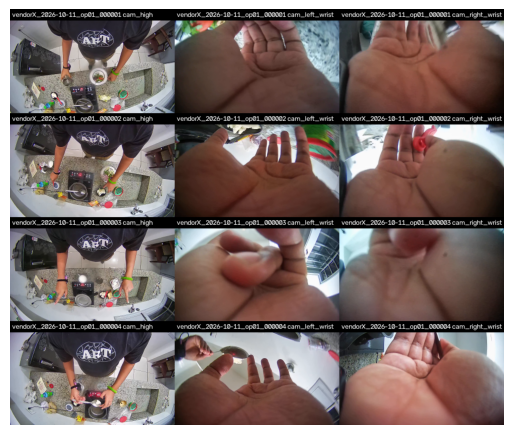

In [11]:
def first_frame(path):
    c = av.open(str(path))
    try:
        for fr in c.decode(video=0):
            return fr.to_ndarray(format="rgb24")
    finally:
        c.close()


try:
    TW, TH, LH = 320, 180, 22
    n_rows = len(EP_IDS)
    canvas = np.zeros((n_rows * (TH + LH), 3 * TW, 3), dtype=np.uint8)
    for ri, eid in enumerate(EP_IDS):
        for ci, cam in enumerate(CAM_NAMES):
            y, x = ri * (TH + LH), ci * TW
            cv2.putText(canvas, f"{eid} {cam}", (x + 4, y + 15), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
            out = EPISODES / eid / "video" / f"{cam}.h264"
            try:
                img = first_frame(out)
                canvas[y + LH:y + LH + TH, x:x + TW] = cv2.resize(img, (TW, TH), interpolation=cv2.INTER_AREA)
            except Exception as e:
                fail(f"contact frame {eid} {cam}", e)
    ok, buf = cv2.imencode(".png", cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))
    (REPORTS / "07_output_contact.png").write_bytes(buf.tobytes())
    plt.figure(figsize=(9, 2.7 * n_rows / 2))
    plt.imshow(canvas)
    plt.axis("off")
    plt.show()
except Exception as e:
    fail("contact sheet", e)

## 10. Hypothesis tests

Check the main expectations and mark each one PASS, FLAG or INFO.

In [12]:
H = []

def add(id_, text, measured, result):
    H.append({"id": id_, "hypothesis": text, "measured": measured, "result": result})

def safe(id_, text, fn):
    try:
        measured, result = fn()
    except Exception as e:
        measured, result = f"not available ({type(e).__name__}: {e})", "FLAG"
    add(id_, text, measured, result)

n_plan = len(plan)

def e1():
    d = check_df
    ok = int(((d["decoded_frames"] == d["plan_frames"]) & (d["decoded_frames"] == d["ts_frames"])).sum())
    return f"{ok} of {n_plan} outputs match plan and timestamps", "PASS" if ok == n_plan == len(d) else "FLAG"

def e2():
    d = check_df
    ok = int(((d["width"] == WIDTH) & (d["height"] == HEIGHT)).sum())
    return f"{ok} of {n_plan} are {WIDTH}x{HEIGHT}", "PASS" if ok == n_plan == len(d) else "FLAG"

def e3():
    # ffprobe often shows the field rate for raw h264, so the timing info in the sps is read as well
    d = check_df
    ok = int(((d["r_frame_rate"] == "30/1") | (d["vui_fps"] == "30/1")).sum())
    seen = ", ".join(sorted(set(d["r_frame_rate"].astype(str))))
    vui = ", ".join(sorted(set(d["vui_fps"].astype(str))))
    return f"{ok} of {n_plan} state 30/1 (ffprobe r_frame_rate: {seen}; sps timing: {vui})", "PASS" if ok == n_plan == len(d) else "FLAG"

def e4():
    good = 0
    for (eid, cam), a in AU.items():
        idx = np.flatnonzero(a["is_key"])
        b = check_df[(check_df["episode_id"] == eid) & (check_df["camera"] == cam)]["b_frames_first300"].iloc[0]
        if np.array_equal(idx, np.arange(0, len(a["is_key"]), 30)) and b == 0:
            good += 1
    return f"{good} of {n_plan} have keyframes every 30 and no B-frames", "PASS" if good == n_plan else "FLAG"

def e5():
    good = 0
    for (eid, cam), a in AU.items():
        dec = check_df[(check_df["episode_id"] == eid) & (check_df["camera"] == cam)]["decoded_frames"].iloc[0]
        k = a["is_key"]
        if len(k) == dec and bool((a["n_sps"][k] > 0).all() and (a["n_pps"][k] > 0).all()):
            good += 1
    return f"{good} of {n_plan} have one unit per frame and SPS/PPS at every keyframe", "PASS" if good == n_plan else "FLAG"

def e6():
    total = int(check_df["freeze_runs"].sum())
    longest = int(check_df["longest_freeze"].max())
    return f"{total} freeze runs of 5 or more frames (longest {longest})", "PASS" if total == 0 else "FLAG"

def e7():
    total = int(check_df["black_runs"].sum())
    n_out = int((check_df["black_runs"] > 0).sum())
    return f"{total} black runs in {n_out} outputs", "INFO"

def e8():
    share = float(align_df["at_zero"].mean())
    return f"{share * 100:.1f} percent of {len(align_df)} samples at offset 0", "PASS" if share >= 0.95 else "FLAG"

def e9():
    parts = []
    for cam in CAM_NAMES:
        m = float(vid_df[vid_df["camera"] == cam]["mbps"].mean())
        parts.append(f"{cam} {m:.2f} Mbps ({'below' if m < 5 else 'above' if m > 8 else 'inside'})")
    return "; ".join(parts), "INFO"

def e10():
    d = check_df
    ok = int(((d["color_range"] == "tv") & (d["color_space"] == "bt709")).sum())
    return f"{ok} of {n_plan} are tv range and bt709", "PASS" if ok == n_plan == len(d) else "FLAG"

def e11():
    return f"{batch['total_gb']} GB in total, {batch['gb_per_hour_3cams']} GB per hour for three cameras", "INFO"

safe("E1", "frame counts equal the plan and the timestamp counts", e1)
safe("E2", "one resolution for all outputs", e2)
safe("E3", "r_frame_rate is 30/1 for all outputs", e3)
safe("E4", "keyframe every 30 frames and no B-frames", e4)
safe("E5", "access unit count equals frame count, SPS and PPS at every keyframe", e5)
safe("E6", "no freeze runs of 5 or more frames", e6)
safe("E7", "black frame runs per output", e7)
safe("E8", "at least 95 percent of alignment samples have the minimum at offset 0", e8)
safe("E9", "bitrate per camera against 5 to 8 Mbps", e9)
safe("E10", "colour range tv and matrix bt709", e10)
safe("E11", "total size and size per hour", e11)

hyp_df = pd.DataFrame(H)
hyp_df.to_csv(REPORTS / "07_hypothesis_check.csv", index=False)
show(hyp_df)

 id                                                            hypothesis                                                                                          measured result
 E1                  frame counts equal the plan and the timestamp counts                                                        12 of 12 outputs match plan and timestamps   PASS
 E2                                        one resolution for all outputs                                                                            12 of 12 are 1920x1080   PASS
 E3                                  r_frame_rate is 30/1 for all outputs                                12 of 12 state 30/1 (ffprobe r_frame_rate: 60/1; sps timing: 30/1)   PASS
 E4                              keyframe every 30 frames and no B-frames                                                  12 of 12 have keyframes every 30 and no B-frames   PASS
 E5   access unit count equals frame count, SPS and PPS at every keyframe                                

## 11. Summary

Write the summary file and the zip with the reports of this step.

In [13]:
try:
    summary = {
        "run_time_utc": RUN_UTC,
        "ffmpeg_version": FFMPEG_VERSION,
        "flags": {"FORCE": FORCE, "PRESET": PRESET, "ROTATE_HEAD_180": ROTATE_HEAD_180,
                  "CRF_CANDIDATES": CRF_CANDIDATES, "TARGET_SSIM": TARGET_SSIM,
                  "BITRATE_CAP_MBPS": BITRATE_CAP_MBPS, "MAKE_MP4_COPY": MAKE_MP4_COPY},
        "crf": CRF,
        "episode_ids": EP_IDS,
        "outputs_planned": int(len(plan)),
        "outputs_found": int(len(vid_df)),
        "total_gb": batch.get("total_gb"),
        "gb_per_hour_3cams": batch.get("gb_per_hour_3cams"),
        "alignment_share_at_0": float(align_df["at_zero"].mean()) if len(align_df) else None,
        "hypotheses": {r["id"]: r["result"] for r in H},
    }
    (REPORTS / "07_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    zip_path = REPORTS / "share_07.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for f in sorted(REPORTS.glob("07_*")):
            if f.is_file():
                zf.write(f, f.name)
    n_pass = sum(1 for r in H if r["result"] == "PASS")
    n_flag = sum(1 for r in H if r["result"] == "FLAG")
    print(f"outputs: {summary['outputs_found']} of {summary['outputs_planned']}")
    print(f"crf {CRF}, preset {PRESET}")
    print(f"size: {summary['total_gb']} GB, {summary['gb_per_hour_3cams']} GB per hour for three cameras")
    print(f"hypotheses: {n_pass} pass, {n_flag} flag")
    print("zip:", zip_path)
except Exception as e:
    fail("summary", e)

outputs: 12 of 12
crf 24, preset veryfast
size: 5.571 GB, 10.191 GB per hour for three cameras
hypotheses: 8 pass, 0 flag
zip: c:\workstation\3RD YEAR\ego_pipeline\reports\share_07.zip
